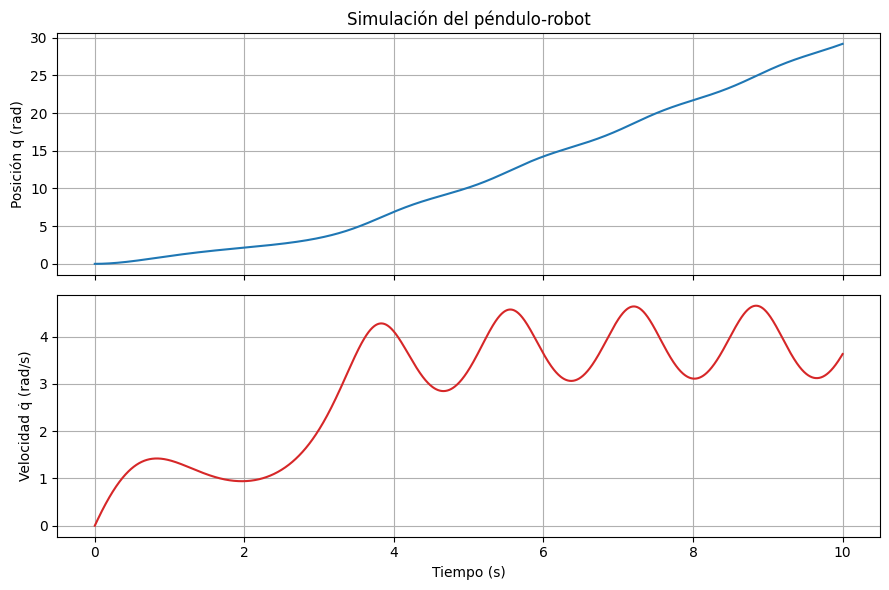

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------- Parámetros ----------
Ir = 0.16    # momento de inercia
m  = 5.0     # masa
g  = 9.81    # gravedad
lc = 0.01    # distancia al centro de masa
b  = 0.14    # viscosidad
fc = 0.45    # fricción de Coulomb

I_total = Ir + m * lc**2   # inercia total en el eje de la articulación

# ---------- Par del motor ----------
def torque(t):
    return 1.0   # escalón de 1 N·m (cámbialo según lo que acuerde el equipo)

# ---------- Modelo en espacio de estados ----------
def pendulo_robot(t, x):
    x1, x2 = x
    # tanh suaviza sign(x2) para evitar problemas numéricos en x2 ≈ 0
    friccion_coulomb = fc * np.tanh(x2 / 1e-3)
    dx1 = x2
    dx2 = (torque(t) - m*g*lc*np.sin(x1) - b*x2 - friccion_coulomb) / I_total
    return [dx1, dx2]

# ---------- Simulación ----------
x0 = [0.0, 0.0]            # X1 = 0, X2 = 0
t_span = (0, 10)           # 10 segundos
t_eval = np.linspace(0, 10, 2000)

sol = solve_ivp(pendulo_robot, t_span, x0, t_eval=t_eval,
                method="RK45", max_step=0.01)

# ---------- Gráficas ----------
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax[0].plot(sol.t, sol.y[0], color="tab:blue")
ax[0].set_ylabel("Posición q (rad)")
ax[0].grid(True)
ax[0].set_title("Simulación del péndulo-robot")

ax[1].plot(sol.t, sol.y[1], color="tab:red")
ax[1].set_ylabel("Velocidad q̇ (rad/s)")
ax[1].set_xlabel("Tiempo (s)")
ax[1].grid(True)

plt.tight_layout()
plt.show()